In [ ]:
import os
if 'SunStatistics' not in os.getcwd():
    os.chdir('../SunStatistics')
import SolarCalc as SC

drange=SC.System(
    Timestamp=['2024-01-01T00:00:00','2026-12-31T23:59:59','30min'],
    Latitude=69.229178,
    Longitude=-135.257278,
    transmissivity=0.6,
    UTC=False,
    Slope=62.5,
    Full_Load_Watts=24,
    Discharge_Limit=0.55,
    Batt_Sequences_in_Parallel=12
    )

# drange = pd.DataFrame(index=pd.date_range(start='2024-01-01T00:00:00',end='2026-12-31T23:59:59',freq='30min'))


In [353]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

def sp(x=1,y=1,kwargs={}):
    return(plt.subplots(x,y,**kwargs))

def quick_filter(
        filename,
        cols,
        ch4_sig = 20,
        irgason_sig = .85,
        qc_thresh = 1,
        u_thresh = .1,
        plot=False,
        q_clip=True
        ):
    df = pd.read_csv(filename,header=[0],skiprows=[0,2],na_values=[-9999])
    df.index = pd.to_datetime(df['date']+' '+df['time'])
    # print(df.columns[df.columns.str.contains('v')])
    # Filter wind dir
    df.loc[((df['wind_dir']>35+180-30)&(df['wind_dir']<35+180+30)),['co2_flux','ch4_flux','LE','H']]=np.nan
    # Filter u*
    df.loc[((df['u*']<u_thresh)),['co2_flux','ch4_flux','LE','H']]=np.nan
    # Other QC
    for f in  ['H','LE','co2_flux','ch4_flux']:
        df.loc[df[f'qc_{f}'].fillna(qc_thresh+1)>=qc_thresh,f]=np.nan
        if f == 'LE':
            if 'h2o_signal_mean' in df.columns:
                df.loc[(df['h2o_signal_mean']<=irgason_sig),'LE']=np.nan
            else:
                df.loc[(df['mean_value_AGC_LI-7500']<=irgason_sig),'LE']=np.nan
        elif f == 'co2_flux':
            if 'co2_signal_mean' in df.columns:
                df.loc[(df[f'co2_signal_mean']>=irgason_sig*100),f]=np.nan
            else:
                df.loc[(df[f'mean_value_AGC_LI-7500']>=irgason_sig*100),f]=np.nan
        elif f == 'ch4_flux':
            if 'ch4_signal_mean' in df.columns:
                df.loc[(df[f'ch4_signal_mean']<=ch4_sig),f]=np.nan
            else:
                df.loc[(df[f'diag_77_mean']<=ch4_sig),f]=np.nan
    df.loc[((df['LE'].isna())|(df['H'].isna())),['co2_flux','ch4_flux']] = np.nan
    # df.loc[(df['x_peak'].isna()),['H','LE','co2_flux','ch4_flux']] = np.nan
    if plot:
        fig,ax=sp(4,kwargs={'sharex':True,'figsize':(10,10)})
        df['ch4_flux'].plot(ax=ax[0],ylabel='umol m-2 s-1',title='FCH4',grid=True)
        df['co2_flux'].plot(ax=ax[1],ylabel='umol m-2 s-1',title='FCO2',grid=True)
        df['LE'].plot(ax=ax[2],ylabel='W m-2',title='LE',grid=True)
        df['H'].plot(ax=ax[3],ylabel='W m-2',title='H',grid=True)
        fig.autofmt_xdate()
        plt.tight_layout()
    s = df['wind_dir'].copy()
    s[s>33+180]-=360
    s.name='wd'
    df = df[[c for c in cols if c in df.columns]].join(s)
    # df = df.join(s)
    df['air_pressure']*=0.001
    if q_clip:
        # cx = ['co2_flux','ch4_flux','LE','H']
        for m in df.index.month.unique():
            for c in ['co2_flux','ch4_flux','LE','H']:
                df.loc[((df.index.month == m) & (df[c]>df.loc[df.index.month==m,c].quantile(.99))),c]=np.nan
                df.loc[((df.index.month == m) & (df[c]<df.loc[df.index.month==m,c].quantile(.01))),c]=np.nan
    return(df)
    

In [ ]:
filename = r"D:\data-dump\SCL\corrected\recalc\eddypro_corrected_v4_full_output_2026-06-14T195313_exp.csv"

cols = ['wind_dir','wind_speed','u*','sonic_temperature',
        'H','qc_H','LE','qc_LE','h2o_signal_mean',
        'co2_flux','qc_co2_flux','co2_signal_mean','co2_mixing_ratio',
        'ch4_flux','qc_ch4_flux','ch4_signal_mean','ch4_mole_fraction',
        'x_peak','air_temperature','air_pressure','x_30%','v_var','daytime']
cols = [c for c in cols if 'qc' not in c]
kwagrs={
    'ch4_sig':20,
    'irgason_sig':.8,
    'qc_thresh':1,
    'u_thresh':.1,
    'plot':False,
    # 'q_clip':False
}

filename = [
    r"D:\data-dump\SCL\EddyPro\2024\eddypro_t_full_output_2025-05-02T224906_exp.csv",
    r"D:\data-dump\SCL\corrected\recalc\eddypro_corrected_v4_full_output_2026-06-14T195313_exp.csv",
    r"D:\data-dump\SCL\EddyPro\eddypro_corrected_v5_2606_full_output_2026-10-08T153810_exp.csv",
    r"D:\data-dump\SCL\EddyPro\eddypro_corrected_v5_260708_full_output_2026-10-08T161521_exp.csv",
    r"D:\data-dump\SCL\EddyPro\eddypro_corrected_v5_2609_full_output_2026-10-08T162421_exp.csv"
    ]
df = pd.concat([quick_filter(fn, cols, **kwagrs) for fn in filename])


df = df.loc[~df.index.duplicated(keep='first')].resample('30min').asfreq()
df = pd.concat([drange,df],axis=1).sort_index()
# df[['co2_flux','ch4_flux']].describe()
# df[['co2_flux','ch4_flux']].plot(subplots=True,figsize=(10,5),grid=True)
df['ch4_flux'] *= 1e3
# df[['H','LE','co2_flux','ch4_flux']].groupby([df.index.month]).agg(['mean','std','count'])
# df.loc[df.index.month==5,'H'].dropna()#


In [357]:
df.loc[df.index.month==4,['co2_flux','ch4_flux']].median()
# df.loc[df.index.month==4,'co2_flux'].plot()

co2_flux    0.019384
ch4_flux    6.637660
dtype: float64

co2_flux
0.40160672676571263
ch4_flux
0.550800061448186


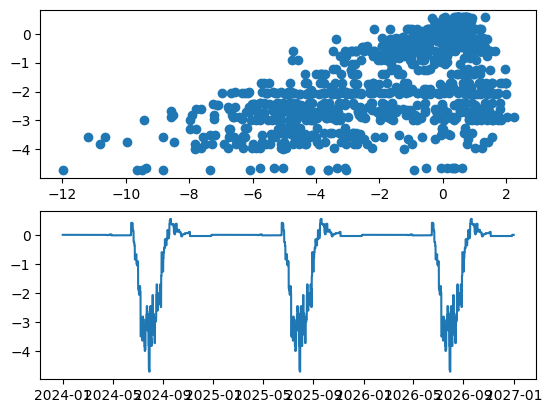

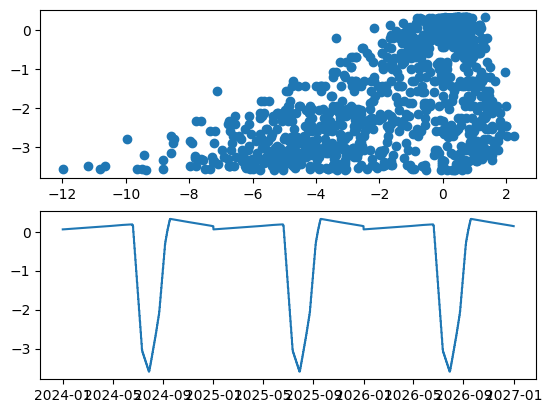

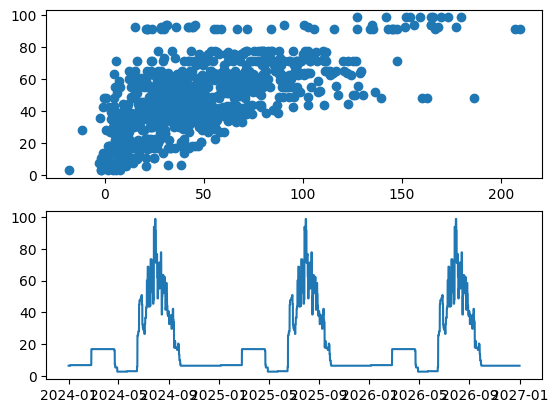

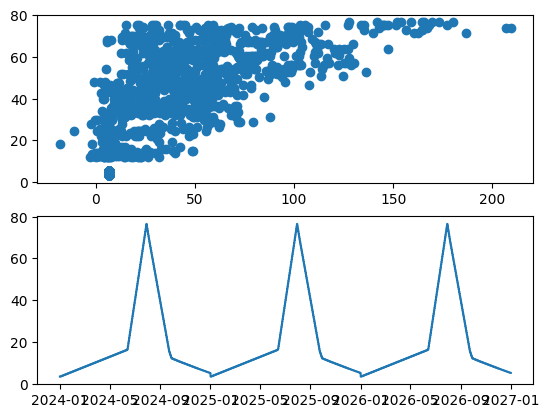

In [362]:
# # df.loc[df.index.month == 4,'ch4_flux'].plot()
# df[['air_temperature','sonic_temperature']].plot()
# df[['ch4_flux','air_temperature']].corr()
# import statsmodels.api as sm
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

x = ['air_temperature','air_pressure','wind_speed','wind_dir','x_peak','DOY','HR','daytime']
df['DOY'] = df.index.dayofyear
df['HR'] = df.index.hour
df['Month'] = df.index.month
df['Year'] = df.index.year
x = ['DOY']#,'HR']
bfx = 5
for c in ['co2_flux','ch4_flux']:
    df.loc[(df.index.dayofyear<=0+bfx)|(df.index.dayofyear>=366-bfx),c] = df.loc[df.index.month==4,c].median()
for y in ['co2_flux','ch4_flux']:
    print(y)
    T = df[[y]+x].dropna()
    Y = T[y].copy()
    X = T[x].copy()
    X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

    rf = RandomForestRegressor(min_samples_leaf=30, random_state=0)
    m = rf.fit(X_train, y_train)
    print(m.score(X_test, y_test))
    fig,ax=plt.subplots(2)
    ax[0].scatter(y_test,m.predict(X_test))
    # HR = np.array([[D,H] for D in range(1,366) for H in range(24)])
    df[f"rf_{y}"] = np.nan
    df.loc[df[x].notna().all(axis=1), f"rf_{y}"] = m.predict(df[x].dropna())
    ax[1].plot(df.index,df[f"rf_{y}"])

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    mlp = MLPRegressor(hidden_layer_sizes=(100, 50), activation='relu', max_iter=500, random_state=42)
    mlp.fit(X_train_scaled, y_train)
    mlp.score(X_test_scaled, y_test)

    fig,ax=plt.subplots(2)
    ax[0].scatter(y_test,mlp.predict(X_test_scaled))
    # predictions = mlp.predict(scaler.transform(df[x].dropna()))
    df[f"mlp_{y}"] = np.nan
    df.loc[df[x].notna().all(axis=1), f"mlp_{y}"] = mlp.predict(scaler.transform(df[x].dropna()))
    ax[1].plot(df.index,df[f"mlp_{y}"])


co2_flux                 rf_co2_flux                 mlp_co2_flux  \
        mean       std count        mean       std count         mean   
1   0.019384  0.000000   720    0.018483  0.000347  4464     0.070782   
2        NaN       NaN     0    0.018100  0.000592  4080     0.093352   
3        NaN       NaN     0    0.016613  0.000000  4464     0.115916   
4   0.008366  0.094129   171    0.016919  0.007772  4320     0.139144   
5        NaN       NaN     0    0.001773  0.001052  4464     0.164725   
6  -0.267468  0.862749   485   -0.136753  0.413755  4320    -0.113443   
7  -3.014454  2.739509  1071   -2.956378  0.912867  4464    -2.941793   
8  -2.340156  2.759975  2302   -2.380488  0.790667  4464    -2.419082   
9  -0.021898  0.948028  1597    0.039845  0.400713  4320     0.033381   
10  0.173013  0.302312   391    0.118513  0.116047  4464     0.277955   
11  0.025988  0.324664   139   -0.002503  0.045527  4320     0.223396   
12  0.019384  0.000000   768   -0.016140  0.014322  4464     0.170072   

                     ch4_flux                  rf_ch4_flux                   \
         std count       mean        std count        mean        std count   
1   0.006805  4464   6.637660   0.000000   720    6.961684   0.124731  4464   
2   0.006224  4080        NaN        NaN     0    8.539895   3.601673  4080   
3   0.006814  4464        NaN        NaN     0   17.041587   0.000000  4464   
4   0.006638  4320  10.603353  10.385802   153   13.666447   5.417460  4320   
5   0.007790  4464        NaN        NaN     0    3.016969   0.139365  4464   
6   0.477420  4320  33.444908  25.123649   321   20.546311  19.174660  4320   
7   0.625644  4464  64.598445  46.031469   956   56.131459  21.037494  4464   
8   0.685325  4464  56.686456  29.678465  2133   56.845472  11.581772  4464   
9   0.367831  4320  26.849995  20.609483  1154   24.277745  10.744487  4320   
10  0.016457  4464        NaN        NaN     0    6.630541   0.000000  4464   
11  0.015088  4320        NaN        NaN     0    6.616843   0.011711  4320   
12  0.015967  4464   6.637660   0.000000   768    6.611142   0.010691  4464   

   mlp_ch4_flux                   
           mean        std count  
1      4.662379   0.703802  4464  
2      6.996822   0.643740  4080  
3      9.330648   0.704779  4464  
4     11.730347   0.682087  4320  
5     14.130047   0.704779  4464  
6     22.520691   7.545717  4320  
7     58.615649  11.441919  4464  
8     56.937515   9.853679  4464  
9     24.112147   8.718509  4320  
10    10.866842   0.706761  4464  
11     8.545889   0.651030  4320  
12     6.307086   0.641540  4464

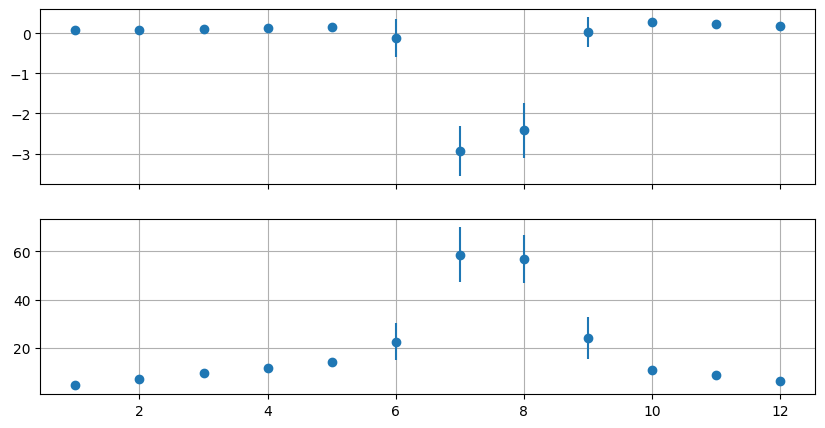

In [363]:
dfx = df[['co2_flux','rf_co2_flux','mlp_co2_flux','ch4_flux','rf_ch4_flux','mlp_ch4_flux']].groupby([df.index.month]).agg(['mean','std','count'])
# dfx[[('mlp_co2_flux','mean'),('mlp_ch4_flux','mean')]].plot(subplots=True,figsize=(10,5),grid=True,yerr=dfx[[('mlp_co2_flux','std'),('mlp_ch4_flux','std')]]
figa,ax=plt.subplots(2,1,figsize=(10,5),sharex=True)
ax[0].errorbar(dfx.index,dfx[('mlp_co2_flux','mean')],yerr=dfx[('mlp_co2_flux','std')],label='MLP',fmt='o')
ax[1].errorbar(dfx.index,dfx[('mlp_ch4_flux','mean')],yerr=dfx[('mlp_ch4_flux','std')],label='MLP',fmt='o')
ax[0].grid(True)
ax[1].grid(True)
mx = df[['co2_flux','ch4_flux']].fillna(df[['mlp_co2_flux','mlp_ch4_flux']]).agg(['mean','std','count']).T
mx['CI'] = 1.96*mx['std']/np.sqrt(mx['count'])
mx = mx[['mean','CI']].T
mx['co2_flux'] *= 44.01*1e-6*3600*24*365#*1e3/3600
mx['ch4_flux'] *= 16.04*1e-9*3600*24*365#*81#*1e3/3600

mx
dfx

994
Background
0.06969617061516588 0.040285398259354885
Seep-affected(300-20/60-75)
1.3024860385532995 0.17557084294970166
Seep-center (20-60)
13.281509202247191 0.9920845823220548


<Axes: xlabel='Wind Direction (deg)', ylabel='FCH4 umol m-2 s-1'>

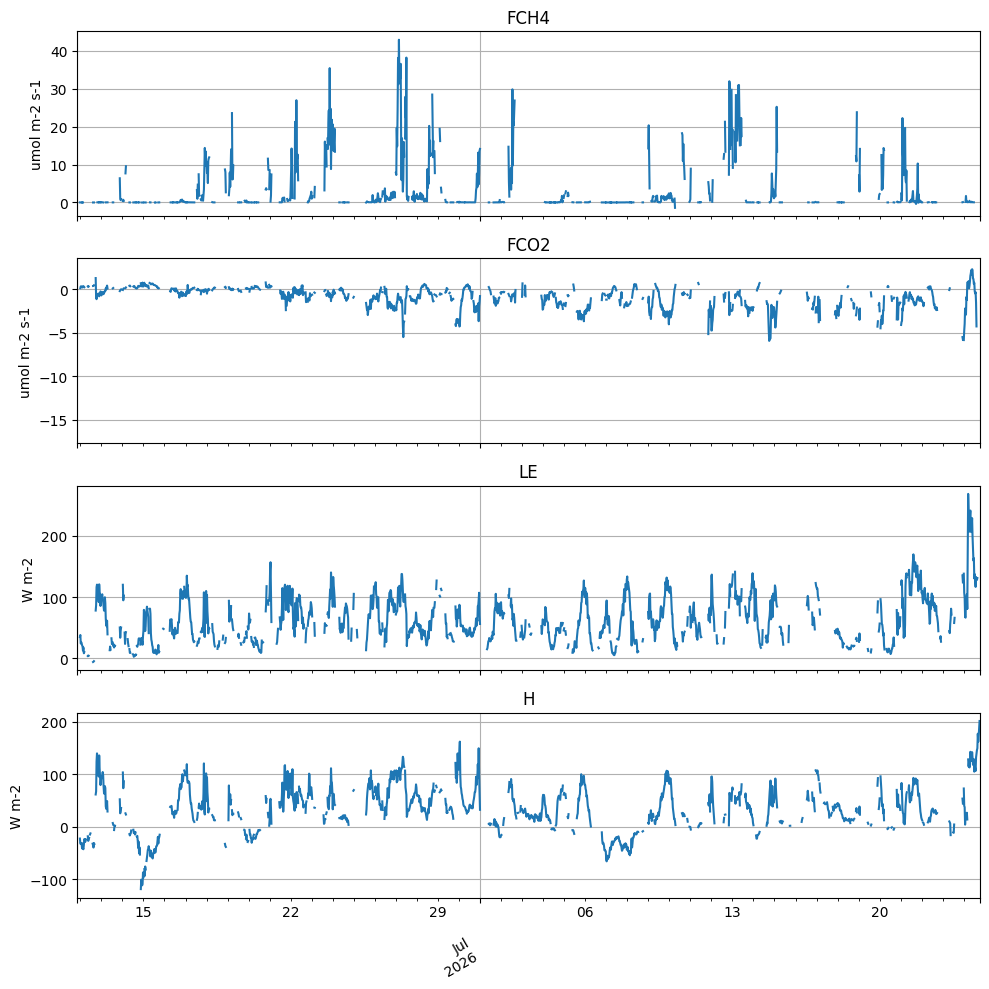

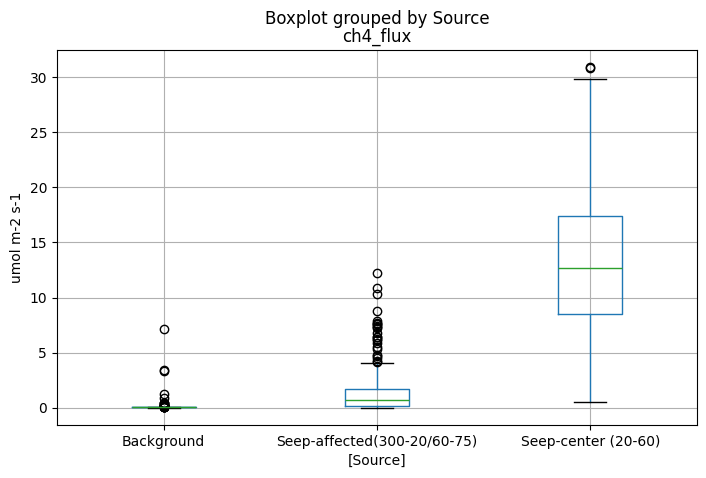

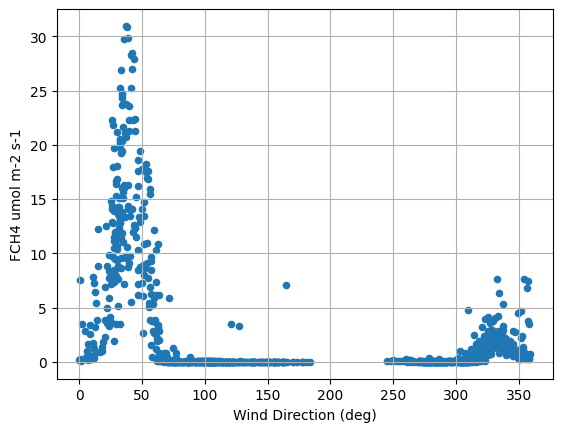

In [316]:

filename = r"D:\data-dump\RDEC1\decompress\out_Test\eddypro_testing_full_output_2026-08-06T113719_exp.csv"
cols = ['wind_dir','wind_speed','u*',
        'H','qc_H','LE','qc_LE','h2o_signal_mean',
        'co2_flux','qc_co2_flux','co2_signal_mean','co2_mixing_ratio',
        'ch4_flux','qc_ch4_flux','ch4_signal_mean','ch4_mole_fraction',
        'x_peak','air_temperature','air_pressure','x_30%','v_var']
cols = [c for c in cols if 'qc' not in c]

kwagrs={
    'ch4_sig':20,
    'irgason_sig':.8,
        'qc_thresh':1,
    'u_thresh':.1,
    'plot':True,
    # 'q_clip':False
}
dfsp = quick_filter(filename,cols,**kwagrs)
dfsp['DOY'] = dfsp.index.dayofyear
dfsp['Hour'] = dfsp.index.hour



dfsp['Source']='Background'
d1,d2=20,60
dfsp.loc[((dfsp['wind_dir']>=d1)&(dfsp['wind_dir']<=d2)),'Source']='Seep-center (20-60)'
d1,d2=0,20
dfsp.loc[((dfsp['wind_dir']>=d1)&(dfsp['wind_dir']<=d2)),'Source']='Seep-affected(300-20/60-75)'
d1,d2=60,75
dfsp.loc[((dfsp['wind_dir']>=d1)&(dfsp['wind_dir']<=d2)),'Source']='Seep-affected(300-20/60-75)'
d1,d2=300,360
dfsp.loc[((dfsp['wind_dir']>=d1)&(dfsp['wind_dir']<=d2)),'Source']='Seep-affected(300-20/60-75)'
print(dfsp['ch4_flux'].count())

for s in dfsp['Source'].unique():
    print(s)
    s = dfsp.loc[dfsp['Source']==s,'ch4_flux'].dropna()
    print(s.mean(),s.std()/s.count()**.5*1.96)

fig,ax=sp(kwargs={'figsize':(8,5)})
# dfsp[]
dfsp[['ch4_flux','Source']].boxplot(by='Source',ax=ax,ylabel='umol m-2 s-1')

# dfsp[['ch4_flux','Source']].groupby('Source').describe().round(3)['ch4_flux'].sort_index(ascending=False)
# ax.set_xticklabels(['Seep-center (20-40)','Seep-adjacent(270-20/60-90)','Background(90-270)'])
dfsp[['ch4_flux','Source']].groupby('Source').describe().round(3)['ch4_flux'].sort_index(ascending=False)


# dfsp[['Source','ch4_spikes','ch4_var']].groupby('Source').describe().round(3).T
fig,ax=sp()
# ax.scatter(dfsp['wind_dir'],dfsp['ch4_flux'])
dfsp.plot(x='wind_dir',y='ch4_flux',kind='scatter',ax=ax,xlabel='Wind Direction (deg)',ylabel='FCH4 umol m-2 s-1',grid=True)

<Axes: >

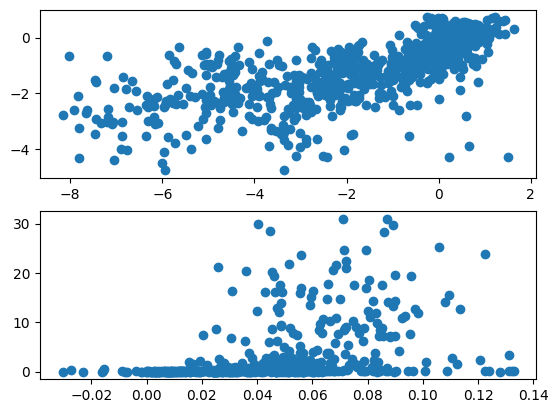

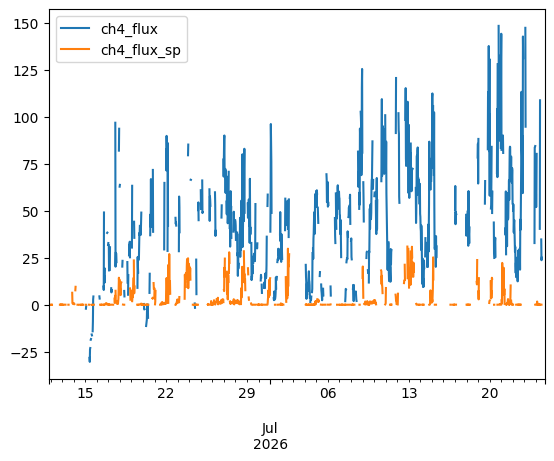

In [323]:
# df['ch']
vx = df.index[df.index.isin(dfsp.index)]
# df.loc[vx].index,dfsp.loc[vx].index
# df.loc[vx,'ch4_flux'].describe()
# df['ch4_flux'].describe()
# dfsp.loc[vx,'ch4_flux'].describe()
T = df.loc[vx,['co2_flux','ch4_flux']].join(dfsp[['co2_flux','ch4_flux']],rsuffix='_sp')
fig,ax=plt.subplots(2)
ax[0].scatter(T['co2_flux'], T['co2_flux_sp'])
ax[1].scatter(T['ch4_flux']*1e-3, T['ch4_flux_sp'])
T.corr()**2

fig,ax=plt.subplots()
T[['ch4_flux','ch4_flux_sp']].plot(ax=ax)

In [272]:

# X = ['air_pressure']
# fig,ax=sp(x=len(X))
# if len(X) == 1:
#     ax = [ax]
# Seep = dfsp.loc[((dfsp['Source']=='Seep-center')&(dfsp['ch4_flux'].notna())&(dfsp[X].notna().all(axis=1)))]
# print(Seep[X].isna().sum())
# Seep['const'] = 1
# lr = sm.OLS(Seep['ch4_flux'],Seep[X + ['const']])
# results = lr.fit()
# result = lr.fit()
# pred = results.predict(Seep[X + ['const']])
# print(results.summary())
# for i in range(len(X)):
#     Seep.plot(x=X[i],y='ch4_flux',kind='scatter',ax=ax[i])
#     ax[i].plot(Seep[X[i]],pred,color='k')
#     # Seep.plot(x=X[1],y='ch4_flux',kind='scatter',ax=ax[1])
#     ax[i].grid()

# _,ax = sp()
# ax.scatter(Seep['ch4_flux'],results.predict(Seep[X + ['const']]),color='k')
# # Seep.loc[Seep[X]<Seep[X].quantile(.1)].sort_values(by=X)

In [ ]:
plt.figure()
plt.scatter(df[''])

In [459]:


# wbin = 'Wind Sector'
# df[wbin] = pd.cut(df['wd'],bins=[-115,-60,25,55,185],labels=['Background','Pond & Isthmus\nWind Dir: 300 to 25 deg','Seep Plume\nWind Dir: 25 to 55deg','Background'],ordered=False)
# fig,ax=sp(kwargs={'figsize':(8,5)})
# def cr(g,y,X):
#     y = g[y]
#     X = pd.DataFrame({ix:np.array(val) for ix,val in g.items() if ix in X})
#     out = np.nan
#     if len(y)>3:
#         X = sm.add_constant(X)
#         lr = sm.OLS(y,X)
#         result = lr.fit()
#         out = [round(result.rsquared_adj,3),round(result.params[X],2),round(result.params['const'],2),len(y),round(result.f_pvalue,3)]
#         if result.rsquared_adj>.1:
#             print(result.summary())
#             ax.scatter(X[X],y,edgecolor='k',)
#             ax.plot(X[X],result.predict(X),
#                     label = f"{g.name}\nr2={out[0]},n={out[3]},p={out[4]}\ny={out[1]}x+{out[2]}")
#     return(out)

# y = 'ch4_flux'
# X=[X]
# grp = wbin
# gp = df[X+[y,grp]].dropna().groupby(grp).agg(list).T.apply(lambda grp: cr(grp,y=y,X=X)).T.rename(columns={0:'r2',1:'m',2:'b',3:'n',4:'p'})
# ax.grid()
# ax.legend()
# ax.set_title('Air pressure vs methane fluxes at the seep site')
# ax.set_ylabel('FCH4 umol m-2 s-1')
# ax.set_xlabel('Air Pressure (kPa)')
# gp
# # df.index.min(),df.index.max()
# # fig,ax=sp()
# # ax.scatter(df['wind_dir'],df['co2_signal_mean'])

<Axes: xlabel='Wind Direction (deg)', ylabel='FCH4 umol m-2 s-1'>

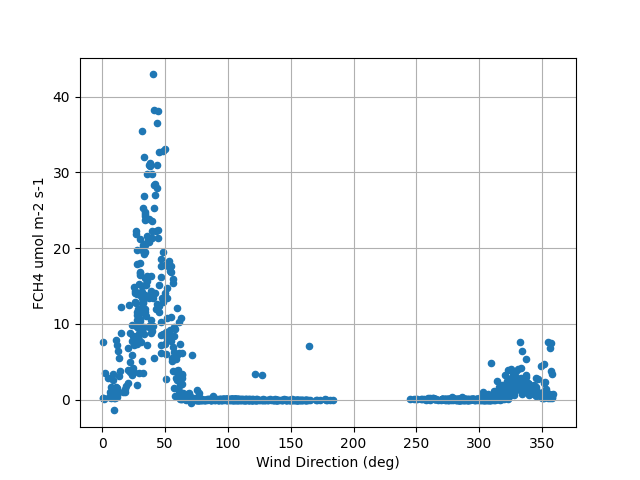

In [ ]:
# df.plot(x='wd',y='ch4_flux',kind='scatter')
# print(df.loc[((df['wd']>100)&(df['ch4_flux']>1)),['ch4_var','ch4_spikes','ch4_flux']])
# ax.set_yscale('symlog')
# df['v_var'].describe()

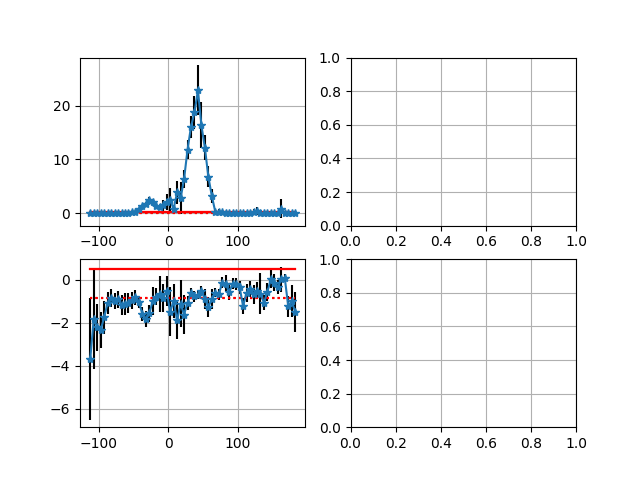

In [441]:
%matplotlib widget
# df['wd'].describe()

by = 5
s = pd.cut(df['wd'],bins=np.arange(-115,185.1,by)).apply(lambda x: x.mid if not type(x) is float else np.nan)
# s = pd.cut(df['wind_dir'],bins=np.arange(0,360.1,by)).apply(lambda x: x.mid)
by = f"by{by}"
s.name = by
gc = df[cols].join(s).groupby(by).agg(['mean','std','count'])
# gc = df.groupby((df['wd']/gscale).round()*gscale).agg(['mean','std','count'])


fig,ax=sp(2,2)
ax = ax.flatten()
ax[0].errorbar(gc.index,gc['ch4_flux']['mean'],yerr=gc['ch4_flux']['std']/gc['ch4_flux']['count']**.5*1.96,marker='*',ecolor='k')
# ax[1].errorbar(gc.index,gc['ch4_mixing_ratio']['mean'],yerr=gc['ch4_mixing_ratio']['std']/gc['ch4_mixing_ratio']['count']**.5*1.96,marker='*',ecolor='k')
for Qcomp,style in zip([.95,1],[':','-']):
    # print(SCL[['ch4_flux','ch4_mixing_ratio']].quantile(Qcomp))
    ax[0].plot(gc.index,gc['ch4_flux']*0+SCL['ch4_flux'].quantile(Qcomp),color='r',linestyle=style)
    # ax[1].plot(gc.index,gc['ch4_mixing_ratio']*0+SCL['ch4_mixing_ratio'].quantile(Qcomp),color='r',linestyle=style)
ax[0].grid()
ax[1].grid()



ax[2].errorbar(gc.index,gc['co2_flux']['mean'],yerr=gc['co2_flux']['std']/gc['co2_flux']['count']**.5*1.96,marker='*',ecolor='k')
# ax[3].errorbar(gc.index,gc['co2_mixing_ratio']['mean'],yerr=gc['co2_mixing_ratio']['std']/gc['co2_mixing_ratio']['count']**.5*1.96,marker='*',ecolor='k')
for Qcomp,style in zip([.25,.75],[':','-']):
    # print(SCL[['co2_flux','co2_mixing_ratio']].quantile(Qcomp))
    ax[2].plot(gc.index,gc['co2_flux']*0+SCL['co2_flux'].quantile(Qcomp),color='r',linestyle=style)
    # ax[3].plot(gc.index,gc['co2_mixing_ratio']*0+SCL['co2_mixing_ratio'].quantile(Qcomp),color='r',linestyle=style)
ax[2].grid()
ax[3].grid()
# fig,ax=plt.subplots()
# ax.scatter(df['co2_mixing_ratio'],df['ch4_mixing_ratio'])

,r2,m,b,n,p
Wind Sector,,,,,
Background,-0.001,0.08,-8.12,478.0,0.57
Pond & Isthmus\nWind Dir: 300 to 25 deg,0.047,0.61,-60.82,304.0,0.00
Seep Plume\nWind Dir: 25 to 55deg,0.098,-3.90,412.70,172.0,0.00


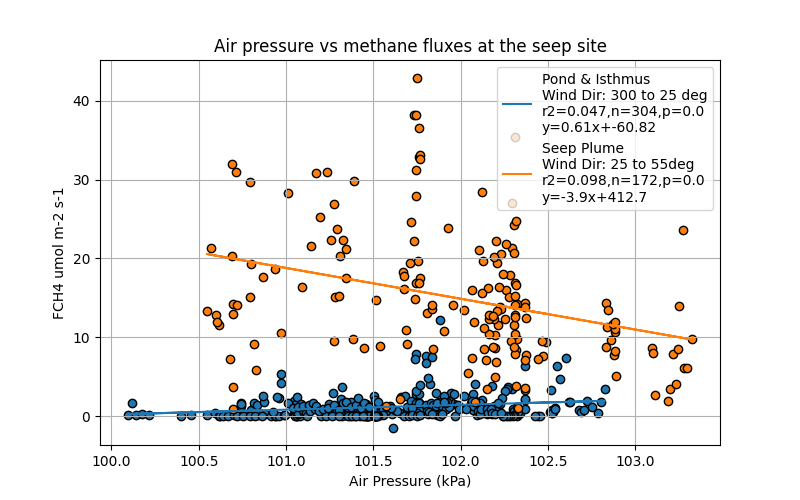